# 06 · Segmentos: perfiles, nombres y recomendaciones

Convierte los cinco clústeres de K-Means en segmentos de negocio: perfil del centroide, nombre
asignado con reglas explícitas, KPIs en unidades reales, validación estadística con variables que
no entraron al modelo y 2–3 acciones de marketing con su KPI.

- **Entrada:** `segments.parquet` y `models/kmeans.joblib` (`uv run poe cluster`),
  `lrfmc.parquet` y `profile.parquet` (`uv run poe features`).
- **Salidas** (`uv run poe segments`): `segment_profiles.csv`, `archetype_scores.csv`,
  `segment_tests.csv` y la columna `segment` en `segments.parquet`.
- Código: `src/segmentacion/segments/{profile,naming,recommendations}.py`. Versión web: página
  **Segmentos**.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import adjusted_rand_score

from segmentacion.config import get_config
from segmentacion.features.lrfmc import LRFMC_COLUMNS
from segmentacion.models.kmeans import fit_kmeans, load_model
from segmentacion.segments.naming import (
    ARCHETYPES,
    archetype,
    archetype_scores,
    assignment_margin,
    name_segments,
    perturbed_archetypes,
)
from segmentacion.segments.profile import (
    association_tests,
    centroids_z,
    segment_kpis,
    trend_z,
)
from segmentacion.segments.recommendations import recommendations_for
from segmentacion.viz import segment_charts as sc
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.float_format", "{:,.3f}".format)
config = get_config()

kmeans = load_model(config.kmeans_file)
features = pd.read_parquet(config.scaled_file)[list(LRFMC_COLUMNS)]
lrfmc = pd.read_parquet(config.lrfmc_file)[list(LRFMC_COLUMNS)]
profile = pd.read_parquet(config.profile_file)
labels = kmeans.labels_
print(f"{len(labels):,} socios · {kmeans.n_clusters} clústeres")

62,044 socios · 5 clústeres


## 1. Centroides en z-score

Los centros de K-Means ya están en el espacio transformado y estandarizado (Yeo-Johnson +
StandardScaler): 0 = socio medio, ±1 = una desviación. Se añade la **tendencia de ingreso (T)**,
que no entró al modelo, estandarizada igual.

In [2]:
centroids = centroids_z(kmeans.cluster_centers_, LRFMC_COLUMNS).join(
    trend_z(labels, profile["revenue_trend"])
)
centroids

,L,R,F,M,C,T
cluster,,,,,,
0,-0.888,-0.415,0.442,0.409,-0.008,0.246
1,0.712,-0.952,1.257,1.207,0.309,0.129
2,-0.509,0.674,-0.984,-0.833,-1.396,-0.120
3,0.906,0.106,-0.159,-0.141,-0.028,0.085
4,-0.360,0.922,-1.002,-1.038,0.735,-0.441


## 2. Nombres por reglas explícitas

Cada arquetipo da un peso a cada feature; la puntuación de un clúster es el producto de su
centroide por los pesos y la asignación óptima (algoritmo húngaro) garantiza nombres únicos.

In [3]:
pd.DataFrame({a.name: a.weights for a in ARCHETYPES}).T.fillna(0).assign(
    regla=[a.rule for a in ARCHETYPES]
)

,F,M,R,C,L,T,regla
VIP,1.000,1.000,-1.000,0.500,0.000,0.000,F↑ M↑ R↓ (C↑)
Nuevos con potencial,0.500,0.000,-1.000,0.000,-1.000,0.000,L↓ R↓ (F↑)
Veteranos ocasionales,-0.500,-0.500,0.000,0.000,1.000,0.000,L↑ (F↓ M↓)
En riesgo de abandono,0.000,0.000,1.000,0.500,0.000,-1.000,R↑ y tendencia de ingreso↓ (C↑)
Cazadores de ofertas,-0.500,0.000,0.000,-1.000,0.000,0.000,C↓ (F↓)


In [4]:
names = name_segments(centroids)
scores = archetype_scores(centroids)
scores.assign(asignado=scores.index.map(names), margen=assignment_margin(centroids, names))

,VIP,Nuevos con potencial,Veteranos ocasionales,En riesgo de abandono,Cazadores de ofertas,asignado,margen
cluster,,,,,,,
0,1.261,1.523,-1.313,-0.665,-0.213,Nuevos con potencial,0.262
1,3.570,0.869,-0.520,-0.926,-0.937,VIP,2.701
2,-3.189,-0.657,0.399,0.097,1.888,Cazadores de ofertas,1.488
3,-0.420,-1.092,1.056,0.008,0.107,Veteranos ocasionales,0.949
4,-2.595,-1.063,0.660,1.731,-0.234,En riesgo de abandono,1.071


Cada clúster recibe el arquetipo con el que más puntúa, así que la asignación óptima coincide
con la elección individual. El margen más pequeño es el de «Nuevos con potencial» frente a «VIP»:
son socios activos que se parecen en parte a los VIP, pero con menos antigüedad y menos vuelos.

### 2.1 ¿Dependen los nombres de los pesos elegidos?

Se repite la asignación 500 veces multiplicando cada peso por un factor aleatorio entre 0,7 y 1,3
(±30 %).

In [5]:
rng = np.random.default_rng(config.random_state)
same = [name_segments(centroids, perturbed_archetypes(0.3, rng)) == names for _ in range(500)]
print(f"Misma asignación en el {np.mean(same):.1%} de las 500 perturbaciones")

Misma asignación en el 100.0% de las 500 perturbaciones


### 2.2 ¿Y de la semilla de K-Means?

Se reentrena K-Means con otras 5 semillas, se nombran sus clústeres con las mismas reglas y se
compara el **nombre** que recibe cada socio con el del modelo final.

In [6]:
final_names = pd.Series(labels).map(names)
rows = []
for seed in range(5):
    model = fit_kmeans(features, kmeans.n_clusters, seed)
    other = centroids_z(model.cluster_centers_, LRFMC_COLUMNS).join(
        trend_z(model.labels_, profile["revenue_trend"])
    )
    other_names = pd.Series(model.labels_).map(name_segments(other))
    rows.append(
        {
            "semilla": seed,
            "mismo_nombre": (other_names == final_names).mean(),
            "ari": adjusted_rand_score(final_names, other_names),
        }
    )
pd.DataFrame(rows).set_index("semilla")

,mismo_nombre,ari
semilla,,
0,0.994,0.985
1,0.996,0.989
2,0.992,0.980
3,0.989,0.974
4,0.993,0.983


Con cualquier semilla, casi todos los socios conservan su nombre: la estabilidad de K-Means
(notebook 05) se traslada a los nombres comerciales.

## 3. KPIs por segmento

In [7]:
kpis = segment_kpis(labels, lrfmc, profile)
kpis.index = kpis.index.map(names)
order = [a.name for a in ARCHETYPES]
kpis.loc[order].T

cluster,VIP,Nuevos con potencial,Veteranos ocasionales,En riesgo de abandono,Cazadores de ofertas
members,"13,240.000","14,359.000","13,480.000","12,049.000","8,916.000"
pct,0.213,0.231,0.217,0.194,0.144
revenue_median,"22,021.000","9,069.000","5,331.500","2,696.000","1,895.000"
revenue_share,0.559,0.232,0.120,0.060,0.028
trend_median,0.058,0.158,0.012,-0.694,-0.168
falling_pct,0.232,0.278,0.392,0.609,0.489
L_median,68.895,23.589,73.758,31.704,28.945
R_median,0.633,1.933,4.167,11.467,8.733
F_median,24.000,11.000,6.000,3.000,3.000
M_median,"34,336.500","15,314.000","9,131.000","3,731.000","4,422.000"


alt.LayerChart(...)
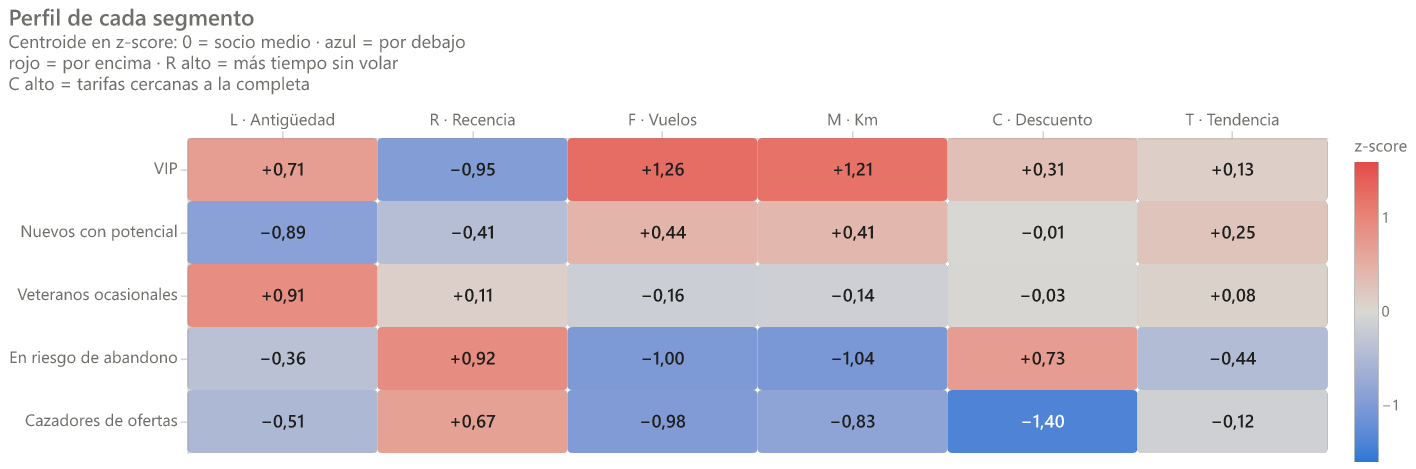

In [8]:
profiles = pd.read_csv(config.segment_profiles_file)
sc.centroid_heatmap(profiles)

alt.Chart(...)
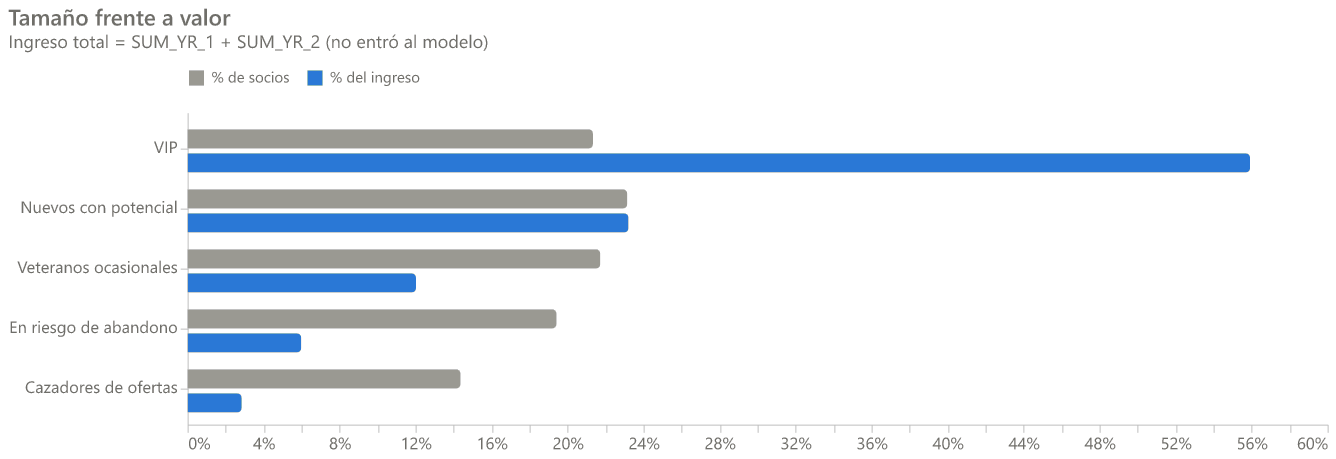

In [9]:
sc.size_value_chart(profiles)

Los **VIP** (≈ 21 % de los socios) generan ≈ 56 % del ingreso. **En riesgo de abandono** y
**Cazadores de ofertas** llevan meses sin volar, pero con precios opuestos (C ≈ 0,82 frente a
≈ 0,50), y en «En riesgo» el 61 % de los socios tiene una caída fuerte de ingreso.

## 4. Validación externa

V de Cramér (categóricas) y ε² de Kruskal-Wallis (numéricas). Con más de 60.000 socios todo es
significativo; lo importante es el tamaño del efecto.

In [10]:
tests = association_tests(labels, profile)
tests

,variable,test,statistic,dof,p_value,effect_name,effect,magnitude
0,FFP_TIER,Chi-cuadrado,"10,243.352",8,0.000,V de Cramér,0.287,mediano
1,GENDER,Chi-cuadrado,"1,007.949",4,0.000,V de Cramér,0.127,pequeño
2,revenue_total,Kruskal-Wallis,"41,764.816",4,0.000,ε²,0.673,grande
3,revenue_trend,Kruskal-Wallis,"3,528.079",4,0.000,ε²,0.057,pequeño
4,AGE,Kruskal-Wallis,"3,375.023",4,0.000,ε²,0.055,pequeño


- **Ingreso total:** efecto **grande** (ε² ≈ 0,67) aunque el ingreso no entró al modelo.
- **Nivel del programa:** efecto **mediano** (V ≈ 0,29); los niveles altos se concentran en VIP.
- **Tendencia de ingreso, edad y género:** efectos **pequeños**. La tendencia apenas no llega a
  mediana porque solo un segmento («En riesgo») cae con fuerza.

**Comprobación:** mediana del ingreso total por segmento (unidades originales).

In [11]:
profile.groupby(pd.Series(labels).map(names).to_numpy())["revenue_total"].describe()[
    ["count", "25%", "50%", "75%"]
].loc[order]

,count,25%,50%,75%
VIP,"13,240.000","14,706.750","22,021.000","35,119.000"
Nuevos con potencial,"14,359.000","6,020.000","9,069.000","13,865.500"
Veteranos ocasionales,"13,480.000","3,501.000","5,331.500","7,911.250"
En riesgo de abandono,"12,049.000","1,800.000","2,696.000","4,137.000"
Cazadores de ofertas,"8,916.000","1,216.750","1,895.000","2,847.500"


## 5. Fichas de segmento

### VIP

*Vuelan mucho, lo han hecho hace poco y pagan tarifas algo por encima de la media: concentran la mayor parte del ingreso.*

**Regla:** F↑ M↑ R↓ (C↑) · **Socios:** 21.3% · **Ingreso:** 55.9% del total · **Ingreso mediano:** 22,021

- **Reconocimiento sin descuento: upgrades, sala VIP y embarque prioritario en sus rutas habituales.** KPI: Tasa de retención a 12 meses y vuelos por socio frente a un grupo de control.
- **Acceso anticipado a ventas y un canal de atención dedicado.** KPI: NPS del segmento y reclamaciones por cada 1.000 vuelos.
- **Alerta temprana cuando un VIP pasa más de 3 meses sin volar, con contacto personal.** KPI: % de VIP que pasan al segmento «En riesgo de abandono» en el trimestre.

alt.LayerChart(...)
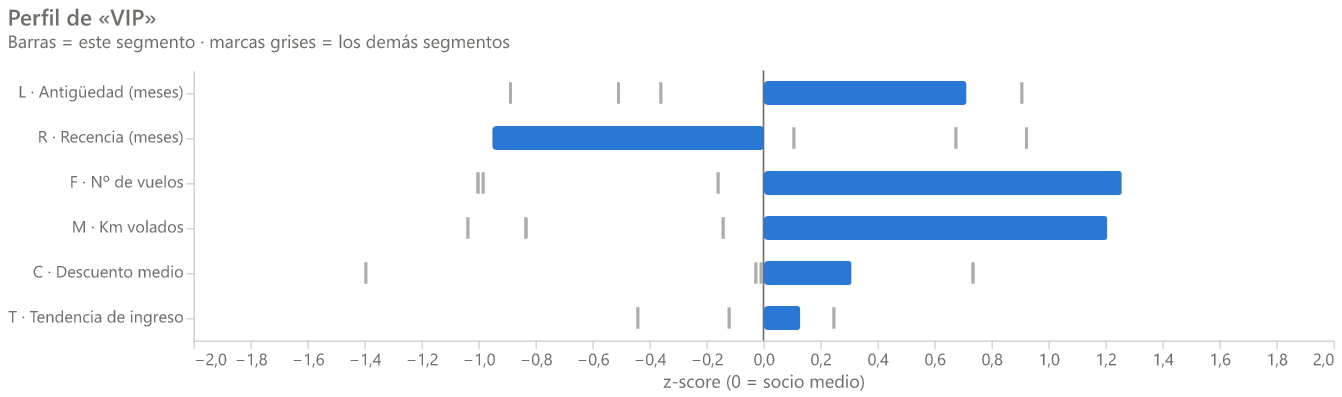

### Nuevos con potencial

*Socios recientes y activos, con más vuelos que la media: el semillero de los futuros VIP.*

**Regla:** L↓ R↓ (F↑) · **Socios:** 23.1% · **Ingreso:** 23.2% del total · **Ingreso mediano:** 9,069

- **Fast track de nivel: millas bonus al alcanzar un número de vuelos en los primeros 6 meses.** KPI: % de socios que suben de nivel (FFP_TIER) en 12 meses.
- **Bono por vuelo adicional y ofertas de rutas nuevas desde su ciudad.** KPI: Vuelos por socio y % que pasa a «VIP» frente a un grupo de control.

alt.LayerChart(...)
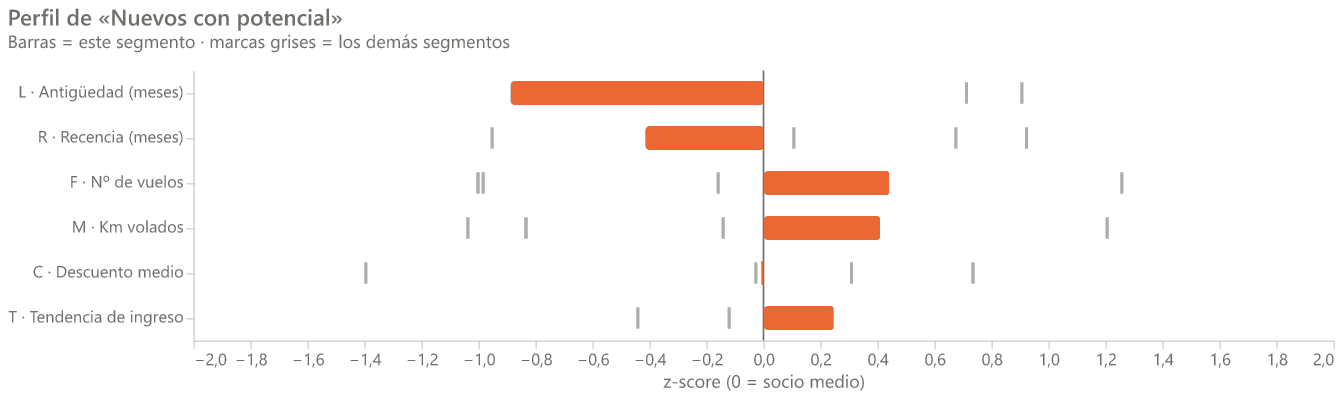

### Veteranos ocasionales

*Socios antiguos que siguen volando, pero poco: una fidelidad de largo plazo con baja frecuencia.*

**Regla:** L↑ (F↓ M↓) · **Socios:** 21.7% · **Ingreso:** 12.0% del total · **Ingreso mediano:** 5,332

- **Campañas de ocio y temporada alineadas con sus fechas habituales de viaje.** KPI: Vuelos por socio al año y tasa de conversión de la campaña.
- **Recordatorio de los puntos acumulados y canjes fáciles para mantener el vínculo.** KPI: Tasa de canje y recencia media del segmento.

alt.LayerChart(...)
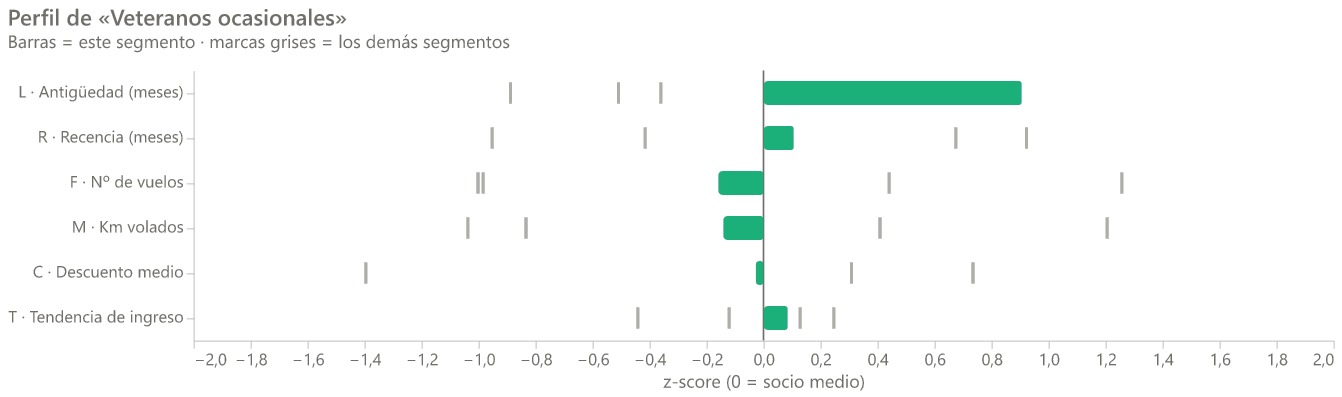

### En riesgo de abandono

*Llevan muchos meses sin volar, sus ingresos caen y pagaban tarifas casi completas: valor que se está perdiendo.*

**Regla:** R↑ y tendencia de ingreso↓ (C↑) · **Socios:** 19.4% · **Ingreso:** 6.0% del total · **Ingreso mediano:** 2,696

- **Win-back con millas extra de caducidad corta (por ejemplo, 90 días).** KPI: % de socios reactivados (al menos un vuelo) en 90 días.
- **Encuesta breve de satisfacción y contacto de servicio al cliente.** KPI: Tasa de respuesta y distribución de los motivos de abandono.
- **Ofrecer upgrades o flexibilidad en lugar de descuentos: pagaban tarifas casi completas.** KPI: Ingreso recuperado por socio contactado frente a un grupo de control.

alt.LayerChart(...)
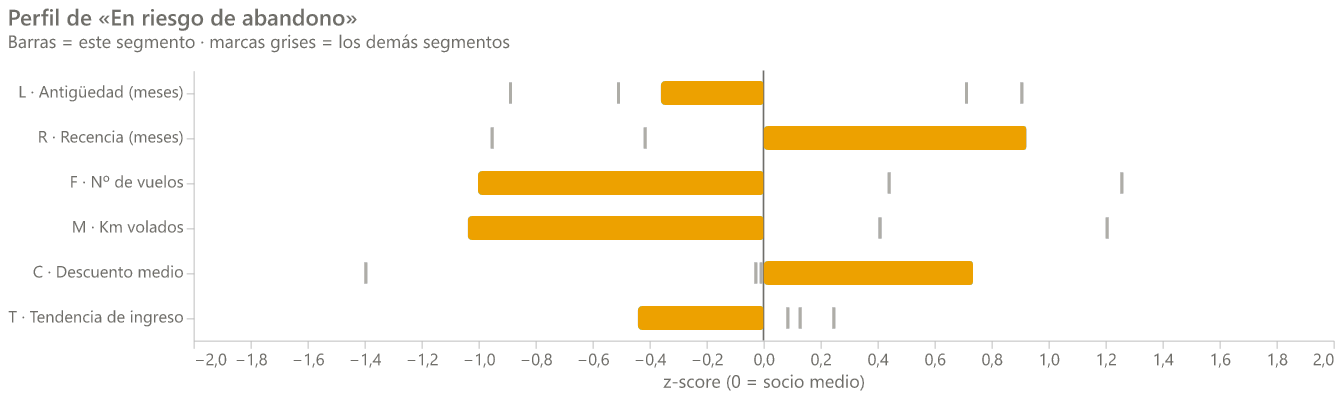

### Cazadores de ofertas

*Compran con mucho descuento y vuelan poco; la mayoría lleva meses sin volar.*

**Regla:** C↓ (F↓) · **Socios:** 14.4% · **Ingreso:** 2.8% del total · **Ingreso mediano:** 1,895

- **Alertas de tarifas promocionales en sus rutas habituales, solo en temporada baja.** KPI: Tasa de reactivación en 90 días e ingreso por km de los vuelos reactivados.
- **Paquetes (vuelo + servicios) en lugar de descuentos generales sobre la tarifa.** KPI: Margen por pasajero frente a una promoción de descuento directo.

alt.LayerChart(...)
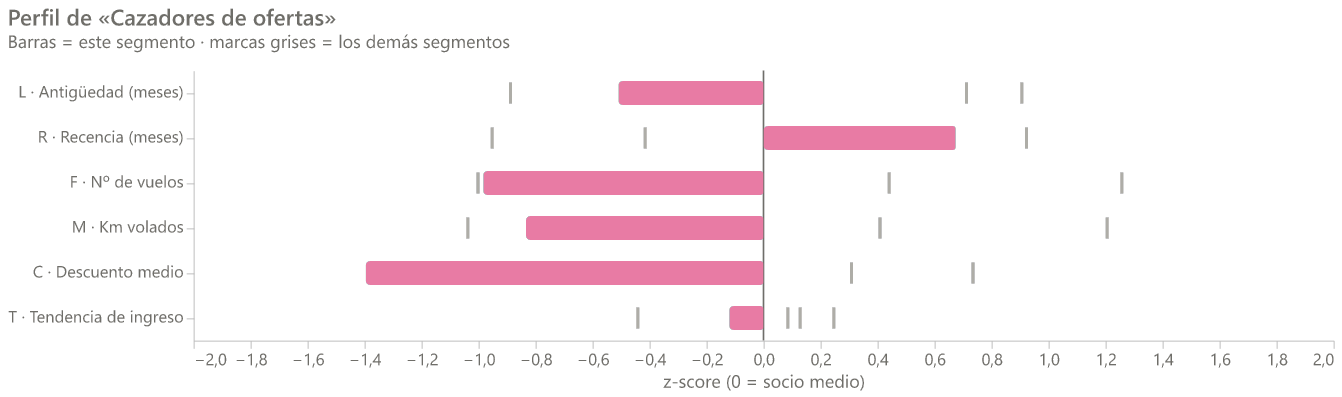

In [12]:
for name in order:
    row = kpis.loc[name]
    actions = "\n".join(f"- **{r.action}** KPI: {r.kpi}" for r in recommendations_for(name))
    display(
        Markdown(
            f"### {name}\n\n*{archetype(name).description}*\n\n"
            f"**Regla:** {archetype(name).rule} · **Socios:** {row['pct']:.1%} · "
            f"**Ingreso:** {row['revenue_share']:.1%} del total · "
            f"**Ingreso mediano:** {row['revenue_median']:,.0f}\n\n{actions}"
        )
    )
    display(sc.segment_profile_chart(profiles, name))

## Conclusiones

- Los cinco clústeres reciben **nombres únicos** con reglas explícitas, y la asignación resiste
  tanto perturbaciones de ±30 % en los pesos como el cambio de semilla de K-Means.
- Los segmentos difieren en **valor real** (ingreso, ε² grande) y en **nivel del programa**
  (efecto mediano), dos variables que no se usaron para segmentar.
- El valor está concentrado en los **VIP** (≈ 21 % de los socios, ≈ 56 % del ingreso). Los dos
  segmentos inactivos (≈ 34 % de los socios) necesitan acciones distintas: *win-back* sin
  descuento para quienes pagaban tarifa completa y ofertas acotadas para los cazadores de
  ofertas.
- Cada segmento tiene 2–3 acciones con su KPI, pensadas para lanzarse como experimentos con
  grupo de control.